<a href="https://colab.research.google.com/github/VARADAkn/FCFSvaradakn/blob/main/SVM_Course_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Handwritten Digit Recognition Using Support Vector Machine
**Machine Learning Course Project**

**Varada K N**

## Objective

The objective of this project is to implement Support Vector Machines (SVM) for linear and nonlinear classification problems and apply them to handwritten digit recognition.

The project consists of three main parts:

1. Soft-Margin SVM using two-dimensional datasets.
2. Handwritten Digit Recognition using Linear SVM.
3. Kernel SVM using the Radial Basis Function (RBF) kernel.

The performance of the classifiers is evaluated using training error, testing error, and decision boundary visualizations.

### Background
A soft margin SVM solves

$$\min_{w,b,\xi}\ \frac12\|w\|^2 + C\sum_{i=1}^{n}\xi_i \quad \text{s.t.}\quad y_i(w^Tx_i+b)\ge 1-\xi_i,\ \ \xi_i\ge 0$$

- **Large C:** violations are penalised heavily, giving a narrower margin (close to hard margin).
- **Small C:** violations are cheap, giving a wider margin and stronger regularization.
- The margin width is $2/\|w\|$.

## 0. Setup and data upload
Run the next cell and upload **`data5.zip`** when asked.

In [2]:
import os, glob, zipfile
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import load_svmlight_file
from sklearn.model_selection import StratifiedKFold, cross_val_score

def find(name):
    hits = [p for p in glob.glob('**/' + name, recursive=True) if '__MACOSX' not in p]
    return hits[0] if hits else None

if find('training_1.txt') is None:
    if not os.path.exists('data5.zip'):
        from google.colab import files
        uploaded = files.upload()
        zip_name = next(iter(uploaded))
    else:
        zip_name = 'data5.zip'
    with zipfile.ZipFile(zip_name) as z:
        z.extractall('.')

print("Data folder:", os.path.dirname(find('training_1.txt')))

Saving data5.zip to data5.zip
Data folder: data5



# Part 1: Soft-Margin Support Vector Machine

## Objective

The objective of this experiment is to implement Soft-Margin SVM using two different two-dimensional datasets.

Each dataset contains two input features and one class label.

The following tasks are performed:

1. Plot the decision boundary using training data.
2. Evaluate the classifier using testing data.
3. Calculate the fraction of misclassified test examples.
4. Experiment with different values of the regularization parameter C.
5. Compare the training and testing errors.


In [3]:
def load_2d(name):
    d = np.loadtxt(find(name))
    return d[:, :2], d[:, 2].astype(int)

X1, y1 = load_2d('training_1.txt'); Xt1, yt1 = load_2d('test_1.txt')
X2, y2 = load_2d('training_2.txt'); Xt2, yt2 = load_2d('test_2.txt')
for n, a, b in [(1, X1, Xt1), (2, X2, Xt2)]:
    print(f"Dataset {n}: {len(a)} training, {len(b)} test samples")

def plot_boundary(model, X, y, ax, title, show_margin=True):
    pad_x, pad_y = 0.05*np.ptp(X[:, 0]), 0.05*np.ptp(X[:, 1])
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-pad_x, X[:, 0].max()+pad_x, 500),
                         np.linspace(X[:, 1].min()-pad_y, X[:, 1].max()+pad_y, 500))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.scatter(*X[y == 1].T, s=10, c='tab:blue', label='+1')
    ax.scatter(*X[y == -1].T, s=10, c='tab:red', marker='x', label='-1')
    ax.contour(xx, yy, Z, levels=[0], colors='k', linewidths=2)
    if show_margin:
        ax.contour(xx, yy, Z, levels=[-1, 1], colors='gray', linestyles='--')
    ax.set_title(title); ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2'); ax.legend()

Dataset 1: 1500 training, 500 test samples
Dataset 2: 1500 training, 500 test samples



### 1.2 Visualization of Decision Boundaries

A linear SVM classifier is trained independently on each dataset using a linear kernel.

The decision boundary represents the hyperplane that separates the two classes.

The margin boundaries corresponding to the decision function values -1 and +1 are also plotted.

The visualization helps understand how SVM separates the training samples into different classes.


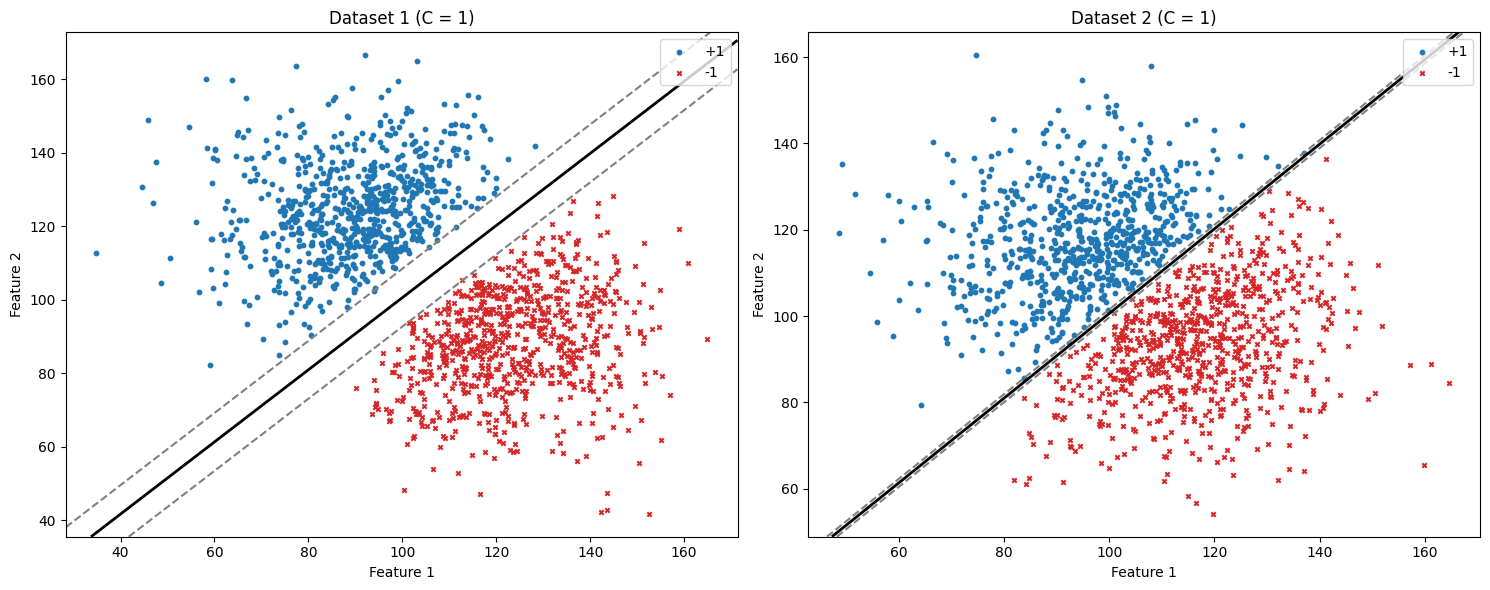

Dataset 1: -0.1247*x1 + 0.1269*x2 + -0.2982 = 0
Dataset 2: -1.0562*x1 + 1.0772*x2 + -2.7619 = 0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
models = {}
for ax, (n, X, y) in zip(axes, [(1, X1, y1), (2, X2, y2)]):
    models[n] = SVC(kernel='linear', C=1).fit(X, y)
    plot_boundary(models[n], X, y, ax, f'Dataset {n} (C = 1)')
plt.tight_layout(); plt.show()

for n, m in models.items():
    w, b = m.coef_[0], m.intercept_[0]
    print(f"Dataset {n}: {w[0]:.4f}*x1 + {w[1]:.4f}*x2 + {b:.4f} = 0")


### 1.3 Evaluation Using Testing Data

The trained SVM classifiers are evaluated using their corresponding testing datasets.

The misclassification fraction is calculated as:


Misclassification Fraction:

$$
\frac{\text{Misclassified Examples}}{\text{Total Test Examples}}
$$

The classification accuracy and misclassification fraction are reported for both datasets.

A lower misclassification fraction indicates better classification performance.


In [ ]:
for n, Xt, yt in [(1, Xt1, yt1), (2, Xt2, yt2)]:
    wrong = np.sum(models[n].predict(Xt) != yt)
    print(f"Dataset {n}: {wrong}/{len(yt)} misclassified, test error = {wrong/len(yt):.4f}")

Dataset 1: 0/500 misclassified, test error = 0.0000
Dataset 2: 0/500 misclassified, test error = 0.0000



### 1.4 Effect of Regularization Parameter C

The regularization parameter C controls the trade-off between maximizing the margin and minimizing classification errors.

Different values of C are considered to investigate their influence on model performance.

- A smaller C allows more classification errors and generally encourages a wider margin.
- A larger C penalizes classification errors more strongly.

Training and testing errors are plotted against different values of C using a logarithmic scale.

The observations help understand the effect of regularization on the SVM classifier.



Dataset 1
       C  Train err   Test err    #SV   Margin
   1e-06     0.0000     0.0000   1274    73.28
   1e-05     0.0000     0.0000    444    35.47
  0.0001     0.0000     0.0000    116    20.71
   0.001     0.0000     0.0000     24    14.26
    0.01     0.0000     0.0000      4    11.56
     0.1     0.0000     0.0000      3    11.24
       1     0.0000     0.0000      3    11.24
      10     0.0000     0.0000      3    11.24
     100     0.0000     0.0000      3    11.24

Dataset 2
       C  Train err   Test err    #SV   Margin
   1e-06     0.0840     0.0980   1450    85.38
   1e-05     0.0007     0.0000    750    30.30
  0.0001     0.0000     0.0000    284    15.22
   0.001     0.0000     0.0000    104     7.59
    0.01     0.0000     0.0000     35     4.21
     0.1     0.0000     0.0000     10     2.41
       1     0.0000     0.0000      5     1.33
      10     0.0000     0.0000      3     1.18
     100     0.0000     0.0000      3     1.18


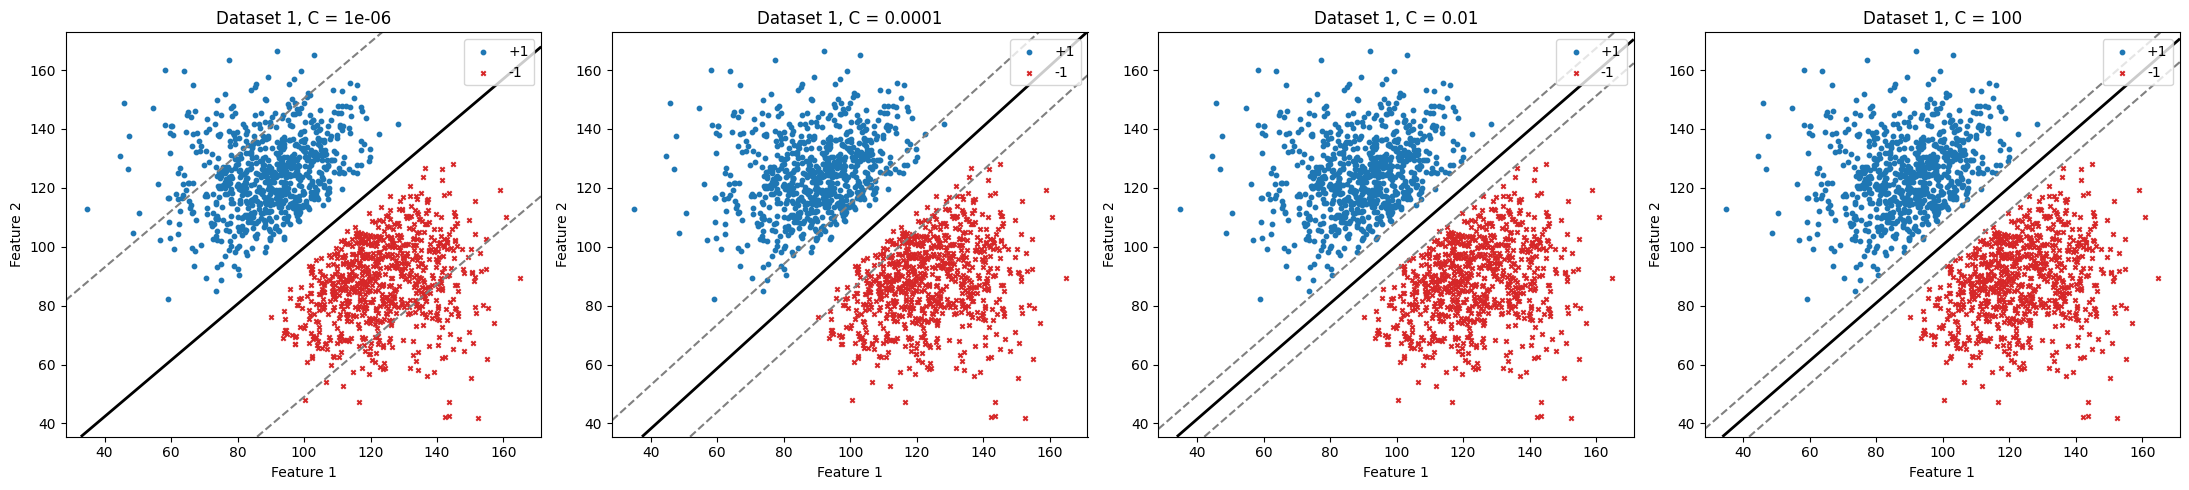

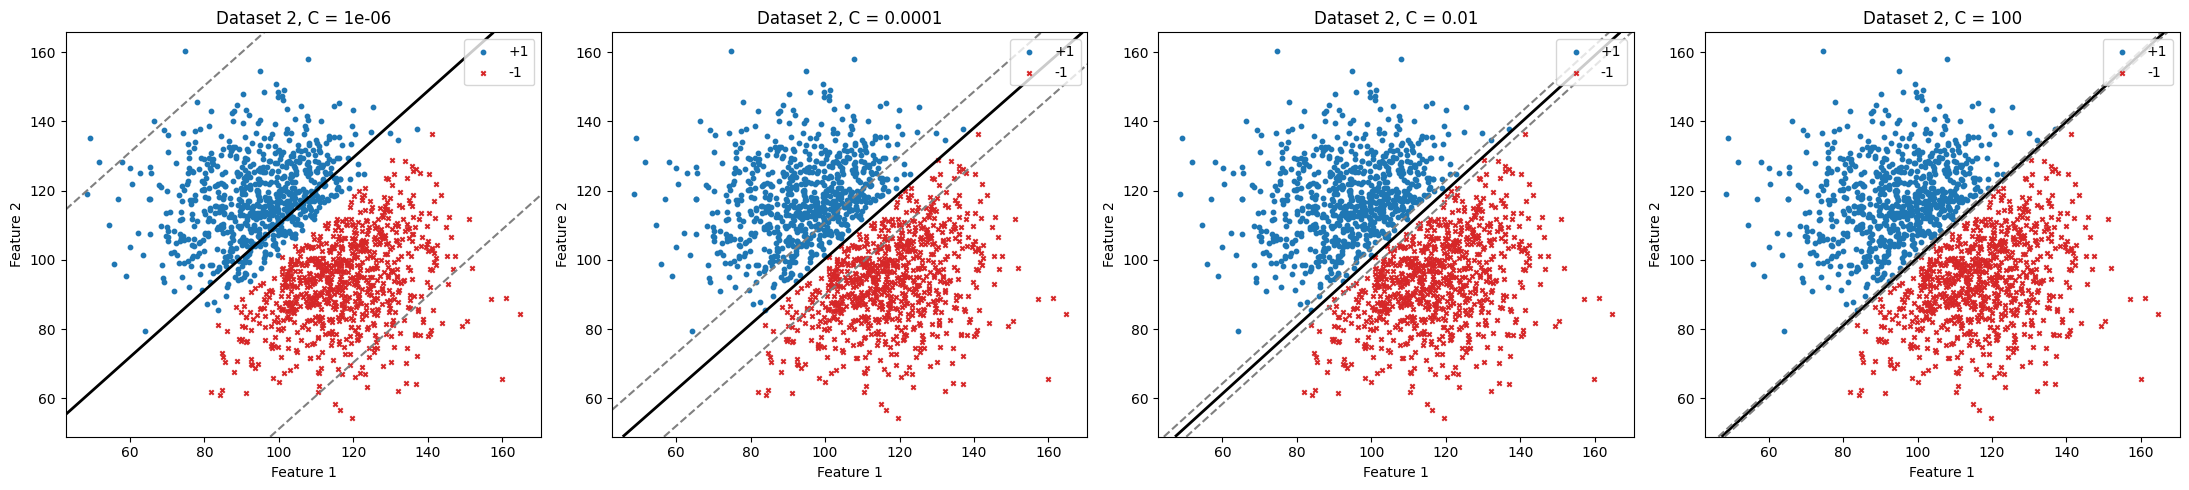

In [ ]:
C_list = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
for n, X, y, Xt, yt in [(1, X1, y1, Xt1, yt1), (2, X2, y2, Xt2, yt2)]:
    print(f"\nDataset {n}")
    print(f"{'C':>8} {'Train err':>10} {'Test err':>10} {'#SV':>6} {'Margin':>8}")
    for C in C_list:
        m = SVC(kernel='linear', C=C).fit(X, y)
        print(f"{C:>8g} {1-m.score(X, y):>10.4f} {1-m.score(Xt, yt):>10.4f} "
              f"{m.n_support_.sum():>6} {2/np.linalg.norm(m.coef_):>8.2f}")

for n, X, y in [(1, X1, y1), (2, X2, y2)]:
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    for ax, C in zip(axes, [1e-6, 1e-4, 1e-2, 100]):
        m = SVC(kernel='linear', C=C).fit(X, y)
        plot_boundary(m, X, y, ax, f'Dataset {n}, C = {C:g}')
    plt.tight_layout(); plt.show()

### Observations
1. **The margin shrinks as C increases.** Dataset 1 goes from about 73.3 (C = 1e-6) to 11.2. Dataset 2 goes from about 85.4 to 1.18.
2. **The number of support vectors falls.** Dataset 1 goes from 1274 to 3, and Dataset 2 from 1450 to 3.
3. **Dataset 1** has 0 training and test error for every C tested. Its classes are well separated.
4. **Dataset 2** underfits at C = 1e-6 (training error 8.40%, test error 9.80%). At C = 1e-5 the training error is 0.07% and the test error is 0. From C = 1e-4 both are 0.
5. **The solution stops changing at large C** (from C = 0.1 for Dataset 1 and C = 10 for Dataset 2). Both datasets are linearly separable, so this is effectively the hard margin solution.
6. Dataset 2 has a much narrower final margin, so its classes lie closer together.


# Part 2: Handwritten Digit Recognition Using Linear SVM

## Objective

The objective of this experiment is to apply a linear Support Vector Machine to recognize handwritten digits.

The classification task is restricted to distinguishing between handwritten digits 0 and 1.

The dataset consists of:

- 12,665 training images.
- 2,115 testing images.
- Each image has a resolution of 28 × 28 pixels.
- Each image is represented using 784 pixel features.

The dataset is provided in sparse LIBSVM format, where only non-zero pixel values are stored.

A linear SVM classifier is trained using the training dataset and evaluated using the testing dataset.


Train: (12665, 784)  Test: (2115, 784)


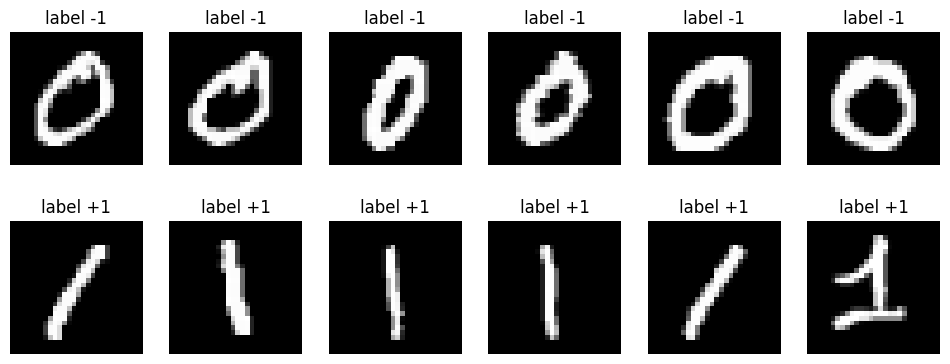

In [ ]:
def load_digits_file(name):
    X, y = load_svmlight_file(find(name), n_features=784, zero_based=False)
    return X.toarray() / 255.0, y.astype(int)

Xtr, ytr = load_digits_file('train-01-images.svm')
Xte, yte = load_digits_file('test-01-images.svm')
print("Train:", Xtr.shape, " Test:", Xte.shape)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for row, label in enumerate([-1, 1]):
    for ax, i in zip(axes[row], np.where(ytr == label)[0][:6]):
        ax.imshow(Xtr[i].reshape(28, 28), cmap='gray')
        ax.set_title(f'label {label:+d}'); ax.axis('off')
plt.show()


### 2(i) Linear SVM with hard margin ($\xi_i = 0$)
scikit-learn has no separate hard margin option, so we use a very large value, $C = 10^{10}$. This makes any violation extremely expensive.

In [ ]:
def errors(model, X, y):
    wrong = np.where(model.predict(X) != y)[0]
    return len(wrong), len(wrong)/len(y), wrong

hard = SVC(kernel='linear', C=1e10, cache_size=1000).fit(Xtr, ytr)
n_tr, hard_train_err, _ = errors(hard, Xtr, ytr)
n_te, hard_test_err, wrong_te = errors(hard, Xte, yte)
print(f"Training error: {n_tr}/{len(ytr)} = {hard_train_err:.5f}")
print(f"Test error    : {n_te}/{len(yte)} = {hard_test_err:.5f} ({hard_test_err*100:.3f}%)")
print("Min y*f(x) on training data:", (ytr*hard.decision_function(Xtr)).min().round(3))

Training error: 0/12665 = 0.00000
Test error    : 2/2115 = 0.00095 (0.095%)
Min y*f(x) on training data: 1.0



#### Analysing a misclassified image
The hard margin SVM has **no misclassified training images**, so none can be picked from it. To study why an SVM gets a training digit wrong, we use a soft margin model with C = 0.01, which is allowed to make some training errors.

C = 0.01 training errors: 9 (0.071%)


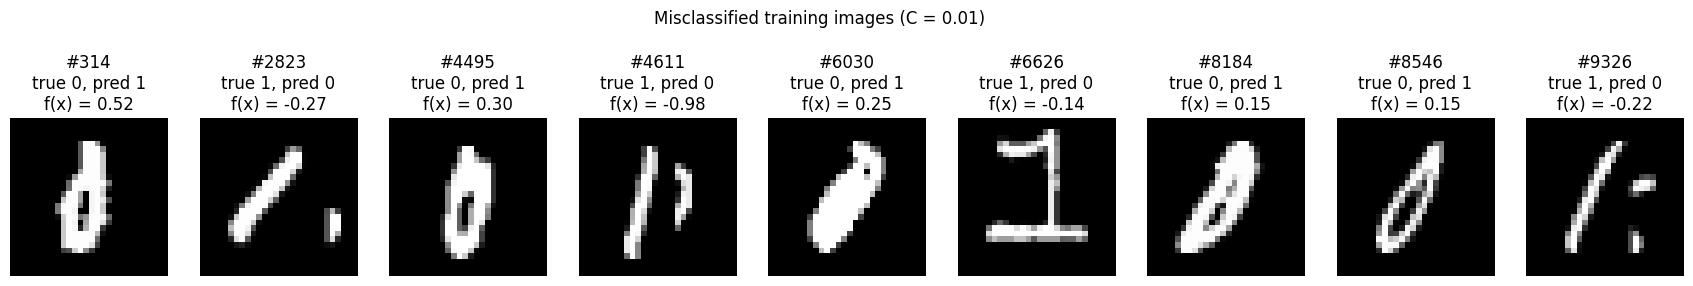

In [ ]:
soft = SVC(kernel='linear', C=0.01, cache_size=1000).fit(Xtr, ytr)
n, e, wrong = errors(soft, Xtr, ytr)
print(f"C = 0.01 training errors: {n} ({e*100:.3f}%)")

def show_images(idx, X, y, model, title):
    cols = len(idx)
    fig, axes = plt.subplots(1, cols, figsize=(2.4*cols, 3.2), squeeze=False)
    for ax, i in zip(axes[0], idx):
        score = model.decision_function(X[i:i+1])[0]
        true, pred = int(y[i] == 1), int(score > 0)
        ax.imshow(X[i].reshape(28, 28), cmap='gray'); ax.axis('off')
        ax.set_title(f'#{i}\ntrue {true}, pred {pred}\nf(x) = {score:.2f}')
    fig.suptitle(title, y=1.08); plt.show()

show_images(wrong, Xtr, ytr, soft, 'Misclassified training images (C = 0.01)')

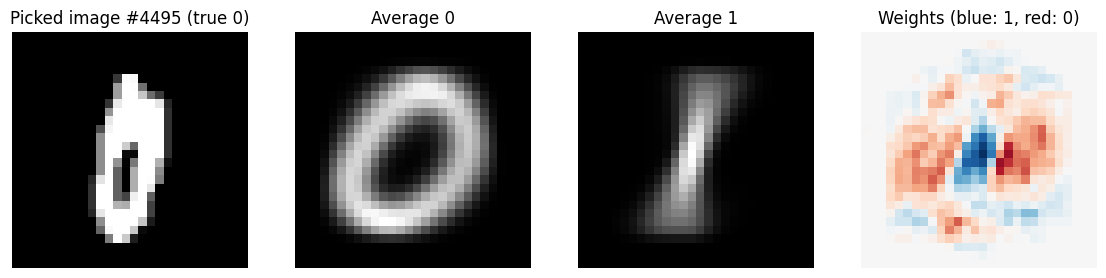

In [ ]:
# The picked example, compared with the average image of each class
i = 4495 if 4495 in wrong else wrong[0]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(Xtr[i].reshape(28, 28), cmap='gray'); axes[0].set_title(f'Picked image #{i} (true {int(ytr[i]==1)})')
axes[1].imshow(Xtr[ytr == -1].mean(0).reshape(28, 28), cmap='gray'); axes[1].set_title('Average 0')
axes[2].imshow(Xtr[ytr == 1].mean(0).reshape(28, 28), cmap='gray'); axes[2].set_title('Average 1')
v = np.abs(soft.coef_).max()
axes[3].imshow(soft.coef_[0].reshape(28, 28), cmap='RdBu', vmin=-v, vmax=v); axes[3].set_title('Weights (blue: 1, red: 0)')
for ax in axes: ax.axis('off')
plt.show()

#### Why does the SVM fail on this image?
Image #4495 is a **0**, but the C = 0.01 model predicts **1**.

- It is a **narrow, upright 0 with thick strokes and a very small hole**. A typical 0 is wide and round with a large empty centre.
- In the weight plot, pixels near the centre have strong weights favouring one class or the other. A narrow 0 puts ink on central pixels that usually indicate a 1.
- A linear SVM only computes a **weighted sum of pixel intensities**. It has no notion of shape, such as "this stroke forms a closed loop", and it is sensitive to changes in width, slant and position.

Several other errors are **1s with a stray blob or broken stroke** beside them, which is noise that looks unlike a typical 1.

With the hard margin (very large C), the model fits even these unusual training images. The two test images it gets wrong are shown below: a very thick 1 and a broken, irregular 0.

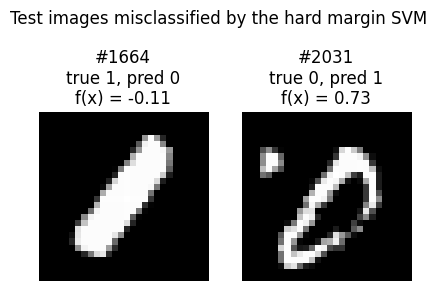

In [ ]:
show_images(wrong_te, Xte, yte, hard, 'Test images misclassified by the hard margin SVM')

### 2(ii) Experimenting with different C
**Estimating the range:** the pixels are in [0, 1] and each image has many active pixels, so $\|x\|^2$ is typically in the tens. A useful C is then expected to be well below 1000. If C is far too small, the model underfits. If C is very large, it behaves like the hard margin SVM. We therefore test **10 values from $10^{-6}$ to $10^{3}$**, spaced logarithmically.



In [ ]:
import time
print("Mean ||x||^2:", (Xtr**2).sum(1).mean().round(1))

# Speed-up: compute all dot products x_i . x_j once and reuse them for every C.
# This is the same linear SVM, only much faster. (K needs about 1.3 GB of RAM.)
K = Xtr @ Xtr.T

Cs = np.logspace(-6, 3, 10)
train_err, test_err = [], []
print(f"{'C':>8} {'Train wrong':>12} {'Train err':>10} {'Test wrong':>11} {'Test err':>10} {'#SV':>6} {'Time':>7}", flush=True)
for C in Cs:
    start = time.time()
    m = SVC(kernel='precomputed', C=C, cache_size=1000).fit(K, ytr)

    # For a linear SVM, f(x) = w.x + b, so prediction is a single matrix product
    w = m.dual_coef_[0] @ Xtr[m.support_]
    b0 = m.intercept_[0]
    a = int(np.sum(np.where(Xtr @ w + b0 > 0, 1, -1) != ytr))
    b = int(np.sum(np.where(Xte @ w + b0 > 0, 1, -1) != yte))

    train_err.append(a/len(ytr)); test_err.append(b/len(yte))
    print(f"{C:>8g} {a:>12} {a/len(ytr):>10.5f} {b:>11} {b/len(yte):>10.5f} {len(m.support_):>6} {time.time()-start:>6.1f}s", flush=True)

Mean ||x||^2: 82.7
       C  Train wrong  Train err  Test wrong   Test err    #SV    Time
   1e-06         5923    0.46767         980    0.46336  11846    7.2s
   1e-05          115    0.00908          11    0.00520   7634    3.3s
  0.0001           30    0.00237           4    0.00189   1808    0.9s
   0.001           18    0.00142           2    0.00095    436    0.3s
    0.01            9    0.00071           1    0.00047    151    0.2s
     0.1            2    0.00016           2    0.00095     89    0.2s
       1            0    0.00000           2    0.00095     84    0.2s
      10            0    0.00000           2    0.00095     84    0.2s
     100            0    0.00000           2    0.00095     84    0.2s
    1000            0    0.00000           2    0.00095     84    0.2s


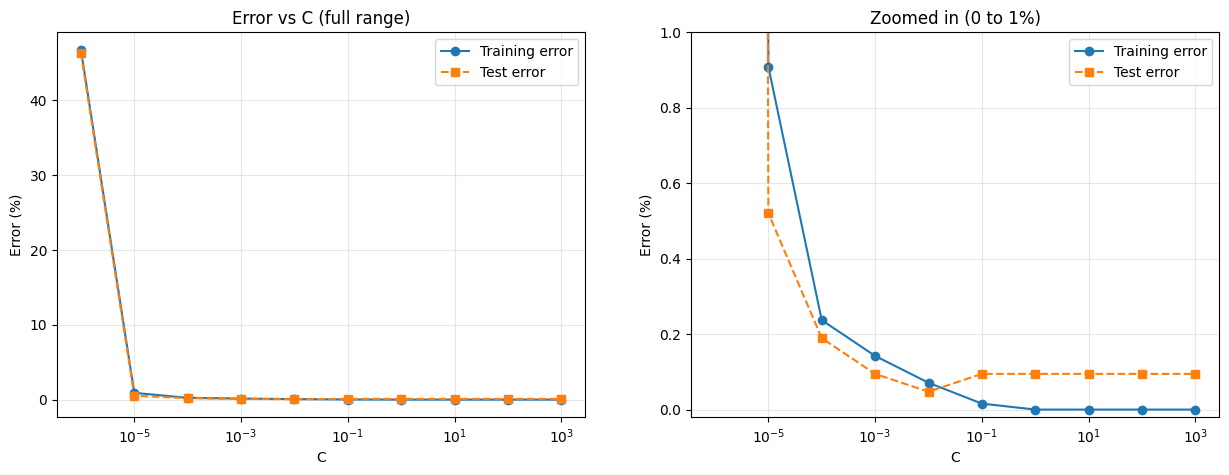

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax in axes:
    ax.plot(Cs, np.array(train_err)*100, 'o-', label='Training error')
    ax.plot(Cs, np.array(test_err)*100, 's--', label='Test error')
    ax.set_xscale('log'); ax.set_xlabel('C'); ax.set_ylabel('Error (%)'); ax.grid(alpha=.3); ax.legend()
axes[0].set_title('Error vs C (full range)')
axes[1].set_title('Zoomed in (0 to 1%)'); axes[1].set_ylim(-0.02, 1)
plt.show()

#### (A) Which C gives the best training error?
The training error is **0 for every tested C from 1 to 1000**. They tie, so we report **C = 1**, the smallest of them and therefore the most regularized.

At C = 1e-6 the training error is about 46.8%, which equals the share of digit 0. The model predicts every image as 1, which is severe underfitting.

#### (B) How does its test error compare with the hard margin test error?
It is **the same: 2/2115, about 0.095%**. At C = 1 and above, no training point needs to violate the margin by enough to change the solution, and it matches the hard margin result.

#### (C) Can we optimize C for the best test error?
**It is possible numerically:** C = 0.01 gives only 1 test error (0.047%), although its training error is higher (9 errors).

**However, this is not a valid way to select C.** Choosing C using the test set leaks test information into the model, so the reported test error becomes optimistically biased. The gain here is also only **one image**, which is too small to show that one model is really better.

The correct method is to select C by **cross-validation on the training data** and use the test set only once at the end.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_Cs = np.logspace(-4, 1, 6)
cv_err = []
for C in cv_Cs:
    acc = cross_val_score(SVC(kernel='precomputed', C=C, cache_size=500), K, ytr, cv=cv)
    cv_err.append(1 - acc.mean())
    print(f"finished C = {C:g}", flush=True)
for C, e in zip(cv_Cs, cv_err):
    print(f"C = {C:<8g} CV error = {e*100:.4f}%")
best_C = cv_Cs[int(np.argmin(cv_err))]
final = SVC(kernel='linear', C=best_C, cache_size=1000).fit(Xtr, ytr)
n, e, _ = errors(final, Xte, yte)
print(f"\nC chosen by CV = {best_C:g}; test error = {n}/{len(yte)} = {e*100:.3f}%")

finished C = 0.0001
finished C = 0.001
finished C = 0.01
finished C = 0.1
finished C = 1
finished C = 10
C = 0.0001   CV error = 0.2369%
C = 0.001    CV error = 0.1658%
C = 0.01     CV error = 0.1026%
C = 0.1      CV error = 0.1026%
C = 1        CV error = 0.1026%
C = 10       CV error = 0.1026%

C chosen by CV = 0.01; test error = 1/2115 = 0.047%


**Result:** C = 0.01, 0.1, 1 and 10 tie at the lowest CV error (0.1026%). The code takes the first of these, **C = 0.01**, which is also the most regularized. It gives a test error of **1/2115 (0.047%)**.

Here the test set was not used to choose C. The difference from the hard margin model is still only one image.

---
## 3. Kernel SVM with the RBF kernel
$$K(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|^2),\quad \gamma>0$$

### 3.1 Plot the data

Samples: 211  Positive: 106  Negative: 105


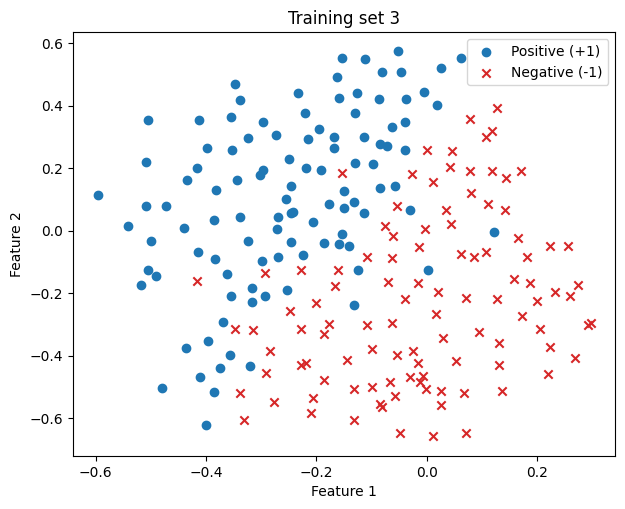

In [ ]:
X3, y3 = load_2d('training_3.text')
print("Samples:", len(y3), " Positive:", (y3 == 1).sum(), " Negative:", (y3 == -1).sum())
plt.figure(figsize=(7, 5.5))
plt.scatter(*X3[y3 == 1].T, c='tab:blue', label='Positive (+1)')
plt.scatter(*X3[y3 == -1].T, c='tab:red', marker='x', label='Negative (-1)')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2'); plt.title('Training set 3'); plt.legend(); plt.show()

Linearly separable? False | The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is Infeasible)
Linear SVM, C = 0.01   training error = 0.4976
Linear SVM, C = 1      training error = 0.0995
Linear SVM, C = 100    training error = 0.0758
Linear SVM, C = 10000  training error = 0.0711


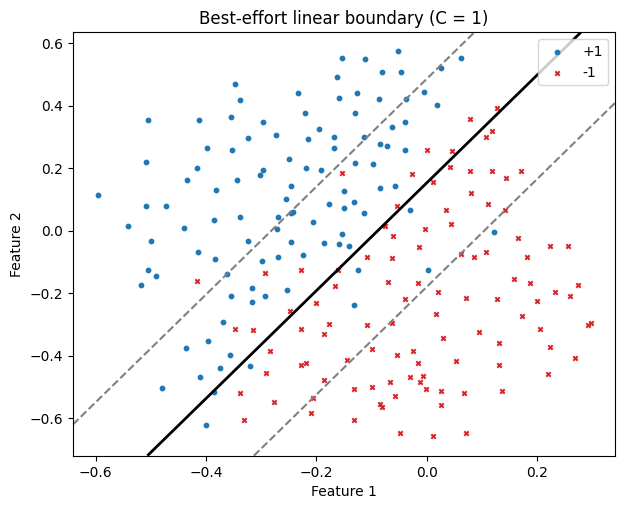

In [ ]:
# Exact test: is there any (w, b) with y_i (w.x_i + b) >= 1 for every point?
from scipy.optimize import linprog
A = -y3[:, None] * np.c_[X3, np.ones(len(y3))]
res = linprog(c=[0, 0, 0], A_ub=A, b_ub=-np.ones(len(y3)), bounds=[(None, None)]*3, method='highs')
print("Linearly separable?", res.status == 0, "|", res.message)

# Check with linear SVMs over several values of C
for C in [0.01, 1, 100, 10000]:
    m = SVC(kernel='linear', C=C).fit(X3, y3)
    print(f"Linear SVM, C = {C:<6g} training error = {1-m.score(X3, y3):.4f}")
plt.figure(figsize=(7, 5.5))
plot_boundary(SVC(kernel='linear', C=1).fit(X3, y3), X3, y3, plt.gca(), 'Best-effort linear boundary (C = 1)')
plt.show()

**Does a linear decision boundary exist?** **No, not one that separates the data perfectly.** The linear program above is infeasible, which means no straight line classifies every point correctly. The scatter plot shows classes split roughly along a diagonal, but some points lie among the opposite class (for example, a positive point near (0.12, 0.0)). A straight line can still classify most points. An RBF kernel allows a non-linear boundary.

### 3.2 RBF SVM with gamma = 100
The assignment does not specify C, so we use **C = 1** for all RBF models.

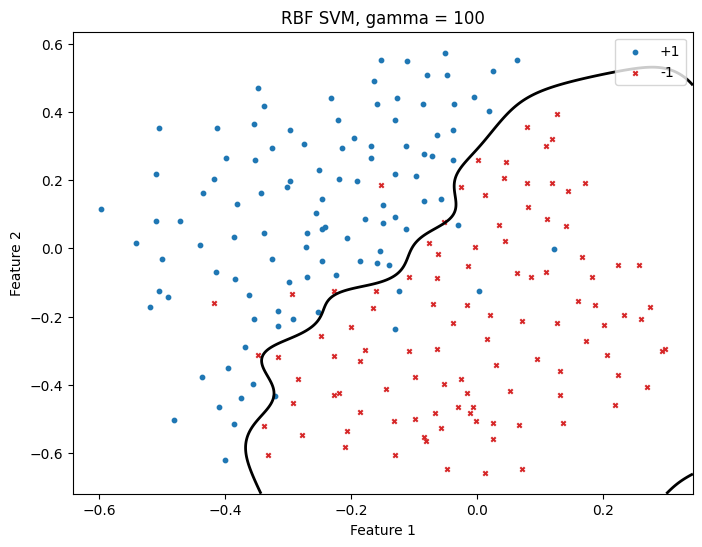

Training error = 0.0569, support vectors = 126


In [ ]:
rbf = SVC(kernel='rbf', gamma=100, C=1).fit(X3, y3)
plt.figure(figsize=(8, 6))
plot_boundary(rbf, X3, y3, plt.gca(), 'RBF SVM, gamma = 100', show_margin=False)
plt.show()
print(f"Training error = {1-rbf.score(X3, y3):.4f}, support vectors = {rbf.n_support_.sum()}")

### 3.3 Comparing gamma = 1, 10, 100, 1000

 gamma  Train err   #SV  5-fold CV err
     1     0.0806    94         0.0946
    10     0.0664    73         0.0804
   100     0.0569   126         0.0898
  1000     0.0000   208         0.1558


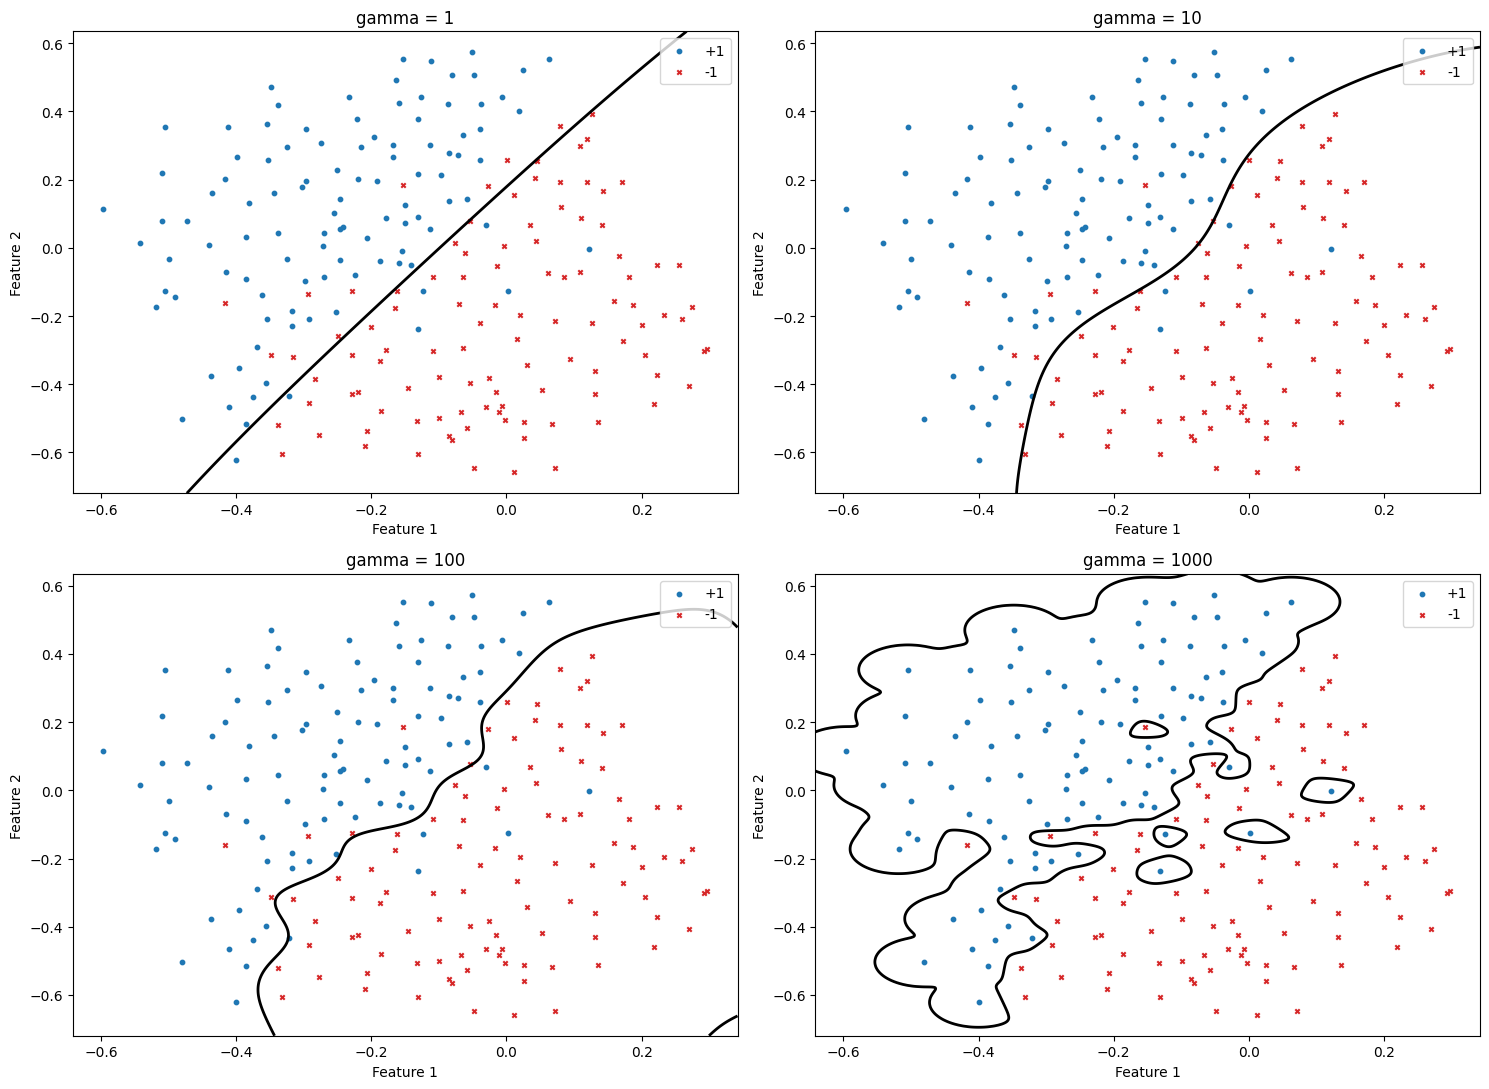

In [ ]:
gammas = [1, 10, 100, 1000]
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
print(f"{'gamma':>6} {'Train err':>10} {'#SV':>5} {'5-fold CV err':>14}")
for ax, g in zip(axes.ravel(), gammas):
    m = SVC(kernel='rbf', gamma=g, C=1).fit(X3, y3)
    plot_boundary(m, X3, y3, ax, f'gamma = {g}', show_margin=False)
    cve = 1 - cross_val_score(SVC(kernel='rbf', gamma=g, C=1), X3, y3, cv=cv).mean()
    print(f"{g:>6} {1-m.score(X3, y3):>10.4f} {m.n_support_.sum():>5} {cve:>14.4f}")
plt.tight_layout(); plt.show()

### How does the boundary change with gamma?
$\gamma$ controls how far the influence of each training point reaches. A larger $\gamma$ means a shorter reach.

| gamma | Boundary shape | Training error | 5-fold CV error | Behaviour |
|---|---|---|---|---|
| 1 | Almost a straight line | 8.06% | 9.46% | Underfits |
| 10 | Smooth curve | 6.64% | **8.04%** | Best of the four |
| 100 | Wiggly curve with local bends | 5.69% | 8.98% | Starts to overfit |
| 1000 | Very irregular, with small islands around single points | 0.00% | 15.58% | Severe overfitting |

As $\gamma$ increases, the boundary becomes **more complex** and the training error falls. Zero training error at $\gamma=1000$ does not mean it is the best model: its cross-validation error is the highest because it fits noise and outliers. Among these four values, **$\gamma = 10$** is estimated to generalize best (with C = 1). The dataset has only 211 points, so small differences in CV error should be read with caution.

---
## Conclusion
- **Soft margin SVM:** increasing C narrows the margin and reduces the number of support vectors. With C = 1, both 2-D datasets had 0 test error.
- **Digit recognition:** the 0/1 training data is linearly separable. The hard margin SVM had 0 training error and 0.095% test error. The model chosen by cross-validation (C = 0.01) had 0.047% test error.
- **RBF kernel:** gamma controls model complexity. Too small a value underfits and too large a value overfits.